In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import shapiro
import scipy.stats as stats

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [55]:
# Load your cleaned dataset
df = pd.read_csv("CONDO_CLEAN.csv")
df.head()

,LOCATION,PRICE,ROOMS,BATHROOMS,CAR_PARKS,PROPERTY_BASE,PROPERTY_TYPE,BUILT-UP,FURNISHING _STATUS
0,BRICKFIELDS,10.0,NaN,NaN,NaN,CONDOMINIUM,OTHER,NaN,NaN
1,CHERAS,408.0,3,2.0,NaN,CONDOMINIUM,OTHER,NaN,NaN
2,KLCC,493.0,1,1.0,NaN,SERVICED RESIDENCE,OTHER,NaN,FULLY FURNISHED
3,CHERAS,530.0,3,2.0,1.0,CONDOMINIUM,INTERMEDIATE,22x70,FULLY FURNISHED
4,SETAPAK,650.0,3,2.0,2.0,SERVICED RESIDENCE,INTERMEDIATE,1270,PARTLY FURNISHED


In [56]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36783 entries, 0 to 36782
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            36783 non-null  object 
 1   PRICE               36631 non-null  float64
 2   ROOMS               36404 non-null  object 
 3   BATHROOMS           36178 non-null  float64
 4   CAR_PARKS           28313 non-null  float64
 5   PROPERTY_BASE       36783 non-null  object 
 6   PROPERTY_TYPE       36782 non-null  object 
 7   BUILT-UP            36024 non-null  object 
 8   FURNISHING _STATUS  32756 non-null  object 
dtypes: float64(3), object(6)
memory usage: 2.5+ MB
None


In [57]:
df.describe()

,PRICE,BATHROOMS,CAR_PARKS
count,3.663100e+04,36178.000000,28313.000000
mean,1.452985e+06,2.641163,1.739943
std,1.461108e+07,1.264609,0.816573
min,1.000000e+01,1.000000,1.000000
25%,5.500000e+05,2.000000,1.000000
50%,8.500000e+05,2.000000,2.000000
75%,1.500000e+06,3.000000,2.000000
max,1.980000e+09,20.000000,13.000000


In [58]:
df['ROOMS'] = pd.to_numeric(df['ROOMS'], errors='coerce')

In [59]:
df['BUILT-UP'] = pd.to_numeric(df['BUILT-UP'], errors='coerce')

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36783 entries, 0 to 36782
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            36783 non-null  object 
 1   PRICE               36631 non-null  float64
 2   ROOMS               36386 non-null  float64
 3   BATHROOMS           36178 non-null  float64
 4   CAR_PARKS           28313 non-null  float64
 5   PROPERTY_BASE       36783 non-null  object 
 6   PROPERTY_TYPE       36782 non-null  object 
 7   BUILT-UP            35928 non-null  float64
 8   FURNISHING _STATUS  32756 non-null  object 
dtypes: float64(5), object(4)
memory usage: 2.5+ MB


In [61]:
missing_counts = df.isnull().sum()
print(missing_counts)

LOCATION                 0
PRICE                  152
ROOMS                  397
BATHROOMS              605
CAR_PARKS             8470
PROPERTY_BASE            0
PROPERTY_TYPE            1
BUILT-UP               855
FURNISHING _STATUS    4027
dtype: int64


In [62]:
df_cleaned = df.dropna()

In [63]:
len(df)-len(df_cleaned) 

12145

In [64]:
has_missing = df.isnull().values.any()
print(has_missing)

True


In [65]:
df_cleaned['ROOMS'].isnull().sum()

np.int64(0)

In [66]:
print(df_cleaned.info())

<class 'pandas.core.frame.DataFrame'>
Index: 24638 entries, 4 to 36624
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            24638 non-null  object 
 1   PRICE               24638 non-null  float64
 2   ROOMS               24638 non-null  float64
 3   BATHROOMS           24638 non-null  float64
 4   CAR_PARKS           24638 non-null  float64
 5   PROPERTY_BASE       24638 non-null  object 
 6   PROPERTY_TYPE       24638 non-null  object 
 7   BUILT-UP            24638 non-null  float64
 8   FURNISHING _STATUS  24638 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.9+ MB
None


In [67]:
# Check dupliation
duplicate_count = df_cleaned.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 2789


In [68]:
# keep='first' (default) marks all duplicates as True except for the first occurrence
duplicate_rows = df_cleaned[df_cleaned.duplicated()]
print(duplicate_rows)

                  LOCATION       PRICE  ROOMS  BATHROOMS  CAR_PARKS  \
135                 PANTAI      2300.0    1.0        2.0        1.0   
183    TAMAN TUN DR ISMAIL      2800.0    3.0        2.0        1.0   
219                   KLCC      3300.0    1.0        2.0        1.0   
220                   KLCC      3300.0    1.0        2.0        1.0   
252                BANGSAR      3900.0    2.0        2.0        2.0   
...                    ...         ...    ...        ...        ...   
36430        BUKIT BINTANG   8800000.0    5.0        5.0        2.0   
36464              BANGSAR   9246600.0    5.0        6.0        3.0   
36492                 KLCC   9600000.0    4.0        4.0        2.0   
36502                 KLCC   9800000.0    7.0        6.0        3.0   
36588                 KLCC  12660000.0    4.0        4.0        2.0   

             PROPERTY_BASE PROPERTY_TYPE  BUILT-UP FURNISHING _STATUS  
135    SERVICED RESIDENCE         DUPLEX     750.0   PARTLY FURNISHED  
183

In [69]:
# remove and update duplicates
df_cleaned.drop_duplicates(inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_16572\2606565119.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned.drop_duplicates(inplace=True)


In [70]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21849 entries, 4 to 36624
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21849 non-null  object 
 1   PRICE               21849 non-null  float64
 2   ROOMS               21849 non-null  float64
 3   BATHROOMS           21849 non-null  float64
 4   CAR_PARKS           21849 non-null  float64
 5   PROPERTY_BASE       21849 non-null  object 
 6   PROPERTY_TYPE       21849 non-null  object 
 7   BUILT-UP            21849 non-null  float64
 8   FURNISHING _STATUS  21849 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.7+ MB


In [71]:
print(df_cleaned.info())


<class 'pandas.core.frame.DataFrame'>
Index: 21849 entries, 4 to 36624
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21849 non-null  object 
 1   PRICE               21849 non-null  float64
 2   ROOMS               21849 non-null  float64
 3   BATHROOMS           21849 non-null  float64
 4   CAR_PARKS           21849 non-null  float64
 5   PROPERTY_BASE       21849 non-null  object 
 6   PROPERTY_TYPE       21849 non-null  object 
 7   BUILT-UP            21849 non-null  float64
 8   FURNISHING _STATUS  21849 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.7+ MB
None


In [72]:
len_after_missing = len(df_cleaned)

In [73]:
len_after_missing 

21849

In [74]:
df_cleaned.describe()

,PRICE,ROOMS,BATHROOMS,CAR_PARKS,BUILT-UP
count,2.184900e+04,21849.000000,21849.000000,21849.000000,21849.000000
mean,1.291826e+06,3.229667,2.646117,1.742505,1712.811145
std,1.358407e+06,1.137224,1.230668,0.824085,8980.611525
min,6.500000e+02,1.000000,1.000000,1.000000,0.000000
25%,5.600000e+05,3.000000,2.000000,1.000000,980.000000
50%,8.400000e+05,3.000000,2.000000,2.000000,1250.000000
75%,1.500000e+06,4.000000,3.000000,2.000000,1711.000000
max,4.054234e+07,11.000000,20.000000,13.000000,790000.000000


In [75]:
df_cleaned['BATHROOMS'].unique()

array([ 2.,  3.,  1.,  4.,  5.,  6.,  8., 20.,  7.,  9., 10.])

In [76]:
# 1. Handle non-numeric text, placeholders, and missing values in BUILT-UP
# Using errors='coerce' forces text like 'nil' or 'unknown' into NaN, which are then dropped.

df_cleaned.dropna(subset=['BUILT-UP'], inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_16572\1097708771.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned.dropna(subset=['BUILT-UP'], inplace=True)


In [77]:
# 2. Filter out likely rental prices and severe low-end price typos
# Keeps only properties where PRICE is RM100,000 or greater
df_cleaned = df_cleaned[df_cleaned['PRICE'] >= 100000]


In [78]:
len_after_price_upper_end = len(df_cleaned)

In [79]:
len(df_cleaned) - len_after_price_upper_end

0

In [80]:
# 3. Remove lower-bound structural errors in BUILT-UP
# Drops values under 100 (fixes decimal typos and sqm vs sqft mix-ups)
df_cleaned = df_cleaned[df_cleaned['BUILT-UP'] >= 100]

In [81]:
len_after_built_up_low_end = len(df_cleaned)

In [82]:
len_after_built_up_low_end

21573

In [83]:
len(df_cleaned)

21573

In [84]:
# 4. Remove extreme upper-bound outliers and systemic duplication errors
# Establishes a strict ceiling of 15,000 sqft
df_cleaned = df_cleaned[df_cleaned['BUILT-UP'] <= 15000]

In [85]:
len_after_built_up_upper_end = len(df_cleaned)

In [86]:
len_after_built_up_upper_end

21558

In [87]:
# Optional: Reset the index after dropping rows to keep the dataframe clean
df_cleaned.reset_index(drop=True, inplace=True)

# Print a quick validation to confirm the current boundaries of the dataset
print(f"Total records remaining: {len(df_cleaned)}")
print(f"PRICE range: RM {df_cleaned['PRICE'].min():,.0f} to RM {df_cleaned['PRICE'].max():,.0f}")
print(f"BUILT-UP range: {df_cleaned['BUILT-UP'].min():,.0f} sqft to {df_cleaned['BUILT-UP'].max():,.0f} sqft")

Total records remaining: 21558
PRICE range: RM 200,000 to RM 40,542,340
BUILT-UP range: 189 sqft to 14,570 sqft


In [88]:
df_cleaned = df_cleaned[df_cleaned['BATHROOMS'] <= 10]

In [89]:
len_after_bathroom = len(df_cleaned)

In [90]:
len_after_bathroom

21556

In [94]:
df_cleaned[df_cleaned['CAR_PARKS'] >= 10]

,LOCATION,PRICE,ROOMS,BATHROOMS,CAR_PARKS,PROPERTY_BASE,PROPERTY_TYPE,BUILT-UP,FURNISHING _STATUS
309,BANDAR MENJALARA,320000.0,3.0,2.0,10.0,SERVICED RESIDENCE,INTERMEDIATE,808.0,UNFURNISHED
3445,SETAPAK,490000.0,4.0,2.0,13.0,CONDOMINIUM,OTHER,1350.0,UNFURNISHED


In [95]:
df_cleaned = df_cleaned[df_cleaned['CAR_PARKS'] < 10]

In [96]:
df_cleaned.describe()

,PRICE,ROOMS,BATHROOMS,CAR_PARKS,BUILT-UP
count,2.155400e+04,21554.000000,21554.000000,21554.000000,21554.000000
mean,1.302386e+06,3.230027,2.645077,1.742507,1551.876264
std,1.345926e+06,1.136887,1.220254,0.817469,988.479112
min,2.000000e+05,1.000000,1.000000,1.000000,189.000000
25%,5.650000e+05,3.000000,2.000000,1.000000,985.000000
50%,8.500000e+05,3.000000,2.000000,2.000000,1250.000000
75%,1.500000e+06,4.000000,3.000000,2.000000,1712.000000
max,4.054234e+07,10.000000,9.000000,9.000000,14570.000000


In [128]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21554 entries, 0 to 21557
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21554 non-null  object 
 1   PRICE               21554 non-null  float64
 2   ROOMS               21554 non-null  float64
 3   BATHROOMS           21554 non-null  float64
 4   CAR_PARKS           21554 non-null  float64
 5   PROPERTY_BASE       21554 non-null  object 
 6   PROPERTY_TYPE       21554 non-null  object 
 7   BUILT-UP            21554 non-null  float64
 8   FURNISHING _STATUS  21554 non-null  object 
 9   PRICE_LOG           21554 non-null  float64
 10  BUILT-UP_LOG        21554 non-null  float64
dtypes: float64(7), object(4)
memory usage: 2.0+ MB


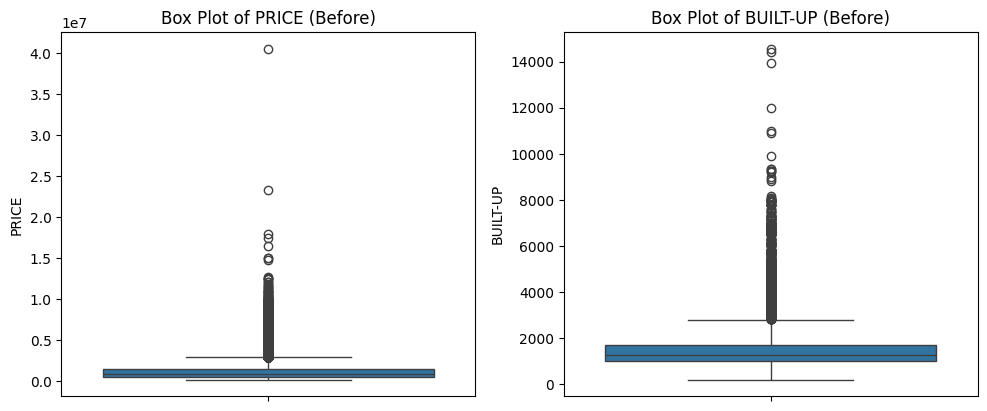

--- Outlier Summary ---
PRICE: 1724 outliers found.
BUILT-UP: 1422 outliers found.

Size before outlier removal: 21554 rows
Size after outlier removal: 18408 rows


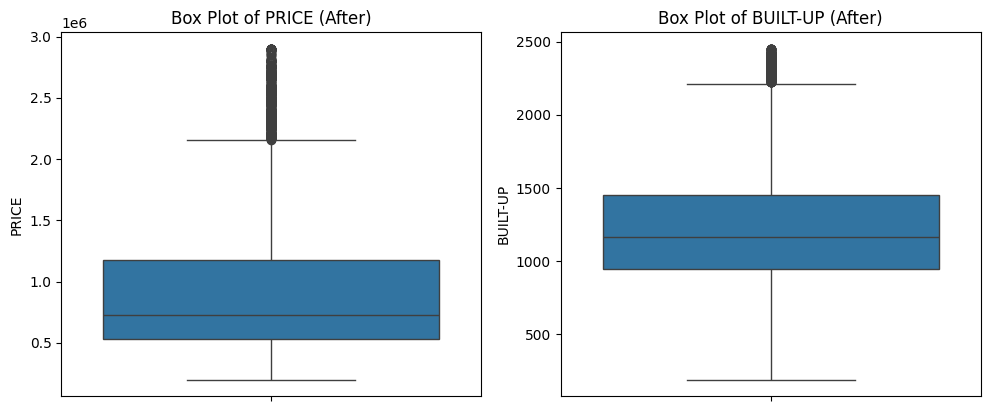

In [129]:
# Check for outliers and remove outliers

# 1. Define your continuous variables
numeric_cols = ['PRICE','BUILT-UP']

# 2. Plot Box Plots BEFORE cleaning (using your existing df_cleaned)
plt.figure(figsize=(15, 8)) 
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_cleaned[col])
    plt.title(f'Box Plot of {col} (Before)')
plt.tight_layout()
plt.show()

# 3. Check and Remove Outliers using IQR
# Create your new variable here by copying the starting data
df_cleaned_iqr = df_cleaned.copy()
size_before_outliers = len(df_cleaned_iqr)

print("--- Outlier Summary ---")
for col in numeric_cols:
    Q1 = df_cleaned_iqr[col].quantile(0.25)
    Q3 = df_cleaned_iqr[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers
    outliers_mask = (df_cleaned_iqr[col] < lower_bound) | (df_cleaned_iqr[col] > upper_bound)
    print(f"{col}: {outliers_mask.sum()} outliers found.")
    
    # Remove outliers and save the result to the new variable
    df_cleaned_iqr = df_cleaned_iqr[(df_cleaned_iqr[col] >= lower_bound) & (df_cleaned_iqr[col] <= upper_bound) | df_cleaned_iqr[col].isna()]

print(f"\nSize before outlier removal: {size_before_outliers} rows")
print(f"Size after outlier removal: {len(df_cleaned_iqr)} rows")

# 4. Plot Box Plots AFTER cleaning (using the new df_cleaned_iqr)
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i) 
    sns.boxplot(y=df_cleaned_iqr[col])
    plt.title(f'Box Plot of {col} (After)')
plt.tight_layout()
plt.show()

In [130]:
df_cleaned_iqr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18408 entries, 0 to 19833
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            18408 non-null  object 
 1   PRICE               18408 non-null  float64
 2   ROOMS               18408 non-null  float64
 3   BATHROOMS           18408 non-null  float64
 4   CAR_PARKS           18408 non-null  float64
 5   PROPERTY_BASE       18408 non-null  object 
 6   PROPERTY_TYPE       18408 non-null  object 
 7   BUILT-UP            18408 non-null  float64
 8   FURNISHING _STATUS  18408 non-null  object 
 9   PRICE_LOG           18408 non-null  float64
 10  BUILT-UP_LOG        18408 non-null  float64
dtypes: float64(7), object(4)
memory usage: 1.7+ MB


In [132]:
df_cleaned_iqr.describe()

,PRICE,ROOMS,BATHROOMS,CAR_PARKS,BUILT-UP,PRICE_LOG,BUILT-UP_LOG
count,1.840800e+04,18408.000000,18408.000000,18408.000000,18408.000000,18408.000000,18408.000000
mean,9.060663e+05,2.987777,2.306280,1.566167,1232.162647,13.580132,7.063855
std,5.066320e+05,0.973330,0.858273,0.626267,404.617244,0.513671,0.330547
min,2.000000e+05,1.000000,1.000000,1.000000,189.000000,12.206078,5.247024
25%,5.300000e+05,2.000000,2.000000,1.000000,947.000000,13.180634,6.854355
50%,7.300000e+05,3.000000,2.000000,2.000000,1163.000000,13.500801,7.059618
75%,1.180000e+06,4.000000,3.000000,2.000000,1454.000000,13.981026,7.282761
max,2.900000e+06,10.000000,8.000000,7.000000,2452.000000,14.880222,7.805067


In [133]:
import csv
df_cleaned_iqr.to_csv('df_cleaned_final_v1.csv', index=False)